In [1]:
import torch

print(torch.cuda.memory_allocated() / 1024**3)
print(torch.cuda.memory_reserved() / 1024**3)

0.0
0.0


<b>LLmma 2 model specif requirement of the prompt defning</b> <br><br>
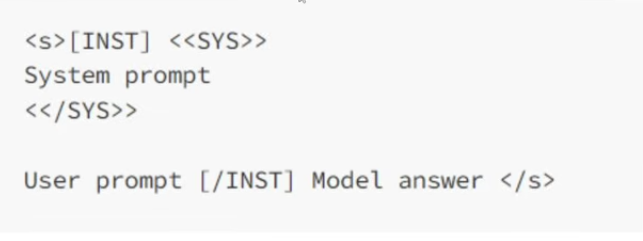

In [2]:
import os

os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import torch
import transformers
import trl
import peft
import bitsandbytes

from datasets import load_dataset
from transformers import (
    AutoModelForCausalLM,
    AutoTokenizer,
    BitsAndBytesConfig,
)
from peft import LoraConfig, prepare_model_for_kbit_training
from trl import SFTConfig, SFTTrainer

if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU was not detected.")

print("GPU:", torch.cuda.get_device_name(0))
print("GPU VRAM:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GiB")
print("Transformers:", transformers.__version__)
print("TRL:", trl.__version__)
print("PEFT:", peft.__version__)
print("BitsAndBytes:", bitsandbytes.__version__)
print("Allocated:", round(torch.cuda.memory_allocated() / 1024**3, 3), "GiB")
print("Reserved:", round(torch.cuda.memory_reserved() / 1024**3, 3), "GiB")

GPU: NVIDIA GeForce RTX 3060
GPU VRAM: 11.63 GiB
Transformers: 5.14.1
TRL: 1.9.2
PEFT: 0.20.0
BitsAndBytes: 0.50.0
Allocated: 0.0 GiB
Reserved: 0.0 GiB


In [3]:
model_name = "NousResearch/Llama-2-7b-chat-hf"
dataset_name = "mlabonne/guanaco-llama2-1k"
output_dir = "./Llama-2-7b-chat-hf-finetune"

supports_bf16 = torch.cuda.is_bf16_supported()

compute_dtype = (
    torch.bfloat16
    if supports_bf16
    else torch.float16
)

print("Compute dtype:", compute_dtype)

Compute dtype: torch.bfloat16


In [4]:
dataset = load_dataset(
    dataset_name,
    split="train",
)

print("Number of examples:", len(dataset))
print("Dataset columns:", dataset.column_names)
print(dataset[0])

Number of examples: 1000
Dataset columns: ['text']
{'text': '<s>[INST] Me gradué hace poco de la carrera de medicina ¿Me podrías aconsejar para conseguir rápidamente un puesto de trabajo? [/INST] Esto vale tanto para médicos como para cualquier otra profesión tras finalizar los estudios aniversarios y mi consejo sería preguntar a cuántas personas haya conocido mejor. En este caso, mi primera opción sería hablar con otros profesionales médicos, echar currículos en hospitales y cualquier centro de salud. En paralelo, trabajaría por mejorar mi marca personal como médico mediante un blog o formas digitales de comunicación como los vídeos. Y, para mejorar las posibilidades de encontrar trabajo, también participaría en congresos y encuentros para conseguir más contactos. Y, además de todo lo anterior, seguiría estudiando para presentarme a las oposiciones y ejercer la medicina en el sector público de mi país. </s>'}


In [5]:
if "text" not in dataset.column_names:
    raise ValueError(
        f"The dataset does not contain a 'text' column. "
        f"Available columns: {dataset.column_names}"
    )

In [6]:
tokenizer = AutoTokenizer.from_pretrained(
    model_name,
    use_fast=True,
)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

tokenizer.padding_side = "right"

print("EOS token:", tokenizer.eos_token)
print("PAD token:", tokenizer.pad_token)

EOS token: </s>
PAD token: <unk>


In [7]:
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=compute_dtype,
    bnb_4bit_use_double_quant=True,
)

In [8]:
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    quantization_config=bnb_config,
    low_cpu_mem_usage=True,
)

model.config.use_cache = False
model.config.pad_token_id = tokenizer.pad_token_id

model = prepare_model_for_kbit_training(
    model,
    use_gradient_checkpointing=True,
)

print("Loaded in 4-bit:", getattr(model, "is_loaded_in_4bit", False))
print(
    "Model footprint:",
    round(model.get_memory_footprint() / 1024**3, 2),
    "GiB",
)
print(
    "GPU allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GiB",
)

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

Loaded in 4-bit: True
Model footprint: 3.99 GiB
GPU allocated: 4.09 GiB


In [9]:
peft_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules="all-linear",
)

In [10]:
training_arguments = SFTConfig(
    output_dir=output_dir,

    num_train_epochs=1,

    # Memory-safe starting point for 12 GB VRAM
    per_device_train_batch_size=1,
    gradient_accumulation_steps=4,

    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={
        "use_reentrant": False,
    },

    learning_rate=2e-4,
    weight_decay=0.001,
    max_grad_norm=0.3,
    warmup_ratio=0.03,
    lr_scheduler_type="cosine",

    optim="paged_adamw_32bit",

    fp16=not supports_bf16,
    bf16=supports_bf16,

    # Dataset configuration belongs in SFTConfig
    dataset_text_field="text",
    max_length=512,
    packing=False,

    logging_steps=10,
    logging_first_step=True,

    save_strategy="epoch",
    save_total_limit=1,

    report_to="tensorboard",
    seed=42,
)

[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


In [11]:
trainer = SFTTrainer(
    model=model,
    args=training_arguments,
    train_dataset=dataset,
    processing_class=tokenizer,
    peft_config=peft_config,
)

trainer.model.print_trainable_parameters()

Tokenizing train dataset:   0%|          | 0/1000 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/1000 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/1000 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/1000 [00:00<?, ? examples/s]

trainable params: 39,976,960 || all params: 6,778,392,576 || trainable%: 0.5898


In [12]:
print(
    "GPU allocated before training:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GiB",
)

train_result = trainer.train()

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'pad_token_id': 0}.


GPU allocated before training: 4.16 GiB


Step,Training Loss
1,2.274341
10,1.687390
20,1.340465
30,1.313606
40,1.226051
50,1.239148
60,1.306395
70,1.277307
80,1.295639
90,1.422668


In [13]:
trainer.save_model(output_dir)
tokenizer.save_pretrained(output_dir)

print("Training completed.")
print("LoRA adapter saved to:", output_dir)

Training completed.
LoRA adapter saved to: ./Llama-2-7b-chat-hf-finetune


In [14]:
trainer.save_model(output_dir)
tokenizer.save_pretrained(output_dir)

print("Adapter saved at:", output_dir)

Adapter saved at: ./Llama-2-7b-chat-hf-finetune


In [15]:
import torch

# Use the model already held by the trainer
test_model = trainer.model
test_model.eval()
test_model.config.use_cache = True

def ask_model(question, max_new_tokens=150):
    prompt = f"""<s>[INST] {question.strip()} [/INST]"""

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        add_special_tokens=False,
    )

    # Put inputs on the model's execution device
    input_device = next(test_model.parameters()).device
    inputs = {
        key: value.to(input_device)
        for key, value in inputs.items()
    }

    with torch.inference_mode():
        output = test_model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=True,
            temperature=0.7,
            top_p=0.9,
            repetition_penalty=1.1,
            pad_token_id=tokenizer.eos_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )

    # Remove the original prompt tokens
    generated_tokens = output[0, inputs["input_ids"].shape[1]:]

    response = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True,
    )

    return response.strip()


In [16]:
response = ask_model(
    "Explain artificial intelligence in simple language."
)

print(response)

Artificial intelligence (AI) refers to the development of computer programs that can perform tasks that typically require human intelligence, such as understanding natural language, recognizing images, and making decisions.

The key idea behind AI is to create machines that can learn from data and make predictions or decisions based on that data. This involves training algorithms with large amounts of data and using those algorithms to recognize patterns and make decisions.

There are many different types of AI, including:

1. Machine learning: This is a type of AI that allows computers to learn from data without being explicitly programmed.
2. Deep learning: This is a type of machine learning that uses neural networks to recognize patterns in large


In [17]:
test_questions = [
    "What is machine learning?",
    "Write a short email requesting leave for two days.",
    "Explain the difference between RAM and storage.",
    "Give five tips for learning Python.",
]

for question in test_questions:
    print("=" * 80)
    print("QUESTION:", question)
    print("ANSWER:", ask_model(question))
    

QUESTION: What is machine learning?
ANSWER: Machine learning (ML) is a subfield of artificial intelligence (AI) that involves the use of algorithms and statistical models to enable machines to learn from data, make decisions, and improve their performance over time.

The basic idea behind ML is that a machine can be trained on a dataset to recognize patterns in the data, make predictions based on those patterns, and then refine its predictions as new data becomes available. This process allows the machine to adapt to changing conditions and improve its accuracy over time.

There are several types of ML, including:

1. Supervised learning: In this type of ML, the machine is trained on a labeled dataset where the correct output is already known. The goal is for the
QUESTION: Write a short email requesting leave for two days.
ANSWER: Subject: Request for Two-Day Leave

Dear [Manager's Name],

I am writing to respectfully request two days of leave from work. I understand that this is a bus